In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from collections import Counter
from sklearn.metrics import accuracy_score

# ==========================================
# 1. Load the Dataset
# ==========================================
print("--- Loading Diabetes Dataset ---")
df = pd.read_csv('diabetes.csv')

print("\n--- First 5 rows of the dataset ---")
display(df.head())

--- Loading Diabetes Dataset ---

--- First 5 rows of the dataset ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,138,62,35,0,33.6,0.127,47,1
1,0,84,82,31,125,38.2,0.233,23,0
2,0,145,0,0,0,44.2,0.630,31,1
3,0,135,68,42,250,42.3,0.365,24,1
4,1,139,62,41,480,40.7,0.536,21,0


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               2768 non-null   int64  
 1   Glucose                   2768 non-null   int64  
 2   BloodPressure             2768 non-null   int64  
 3   SkinThickness             2768 non-null   int64  
 4   Insulin                   2768 non-null   int64  
 5   BMI                       2768 non-null   float64
 6   DiabetesPedigreeFunction  2768 non-null   float64
 7   Age                       2768 non-null   int64  
 8   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 194.8 KB


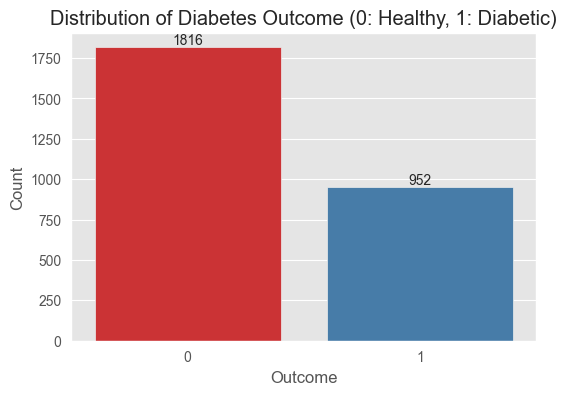

In [57]:
# ==========================================
# 2. Data Visualization (EDA)
# ==========================================
# Plot 1: Target distribution (Updated to fix Seaborn warning)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Outcome', data=df, hue='Outcome', palette='Set1', legend=False)
plt.title('Distribution of Diabetes Outcome (0: Healthy, 1: Diabetic)')
plt.xlabel('Outcome')
plt.ylabel('Count')

# Annotate bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')
plt.show()


--- Plotting Correlation Matrix ---


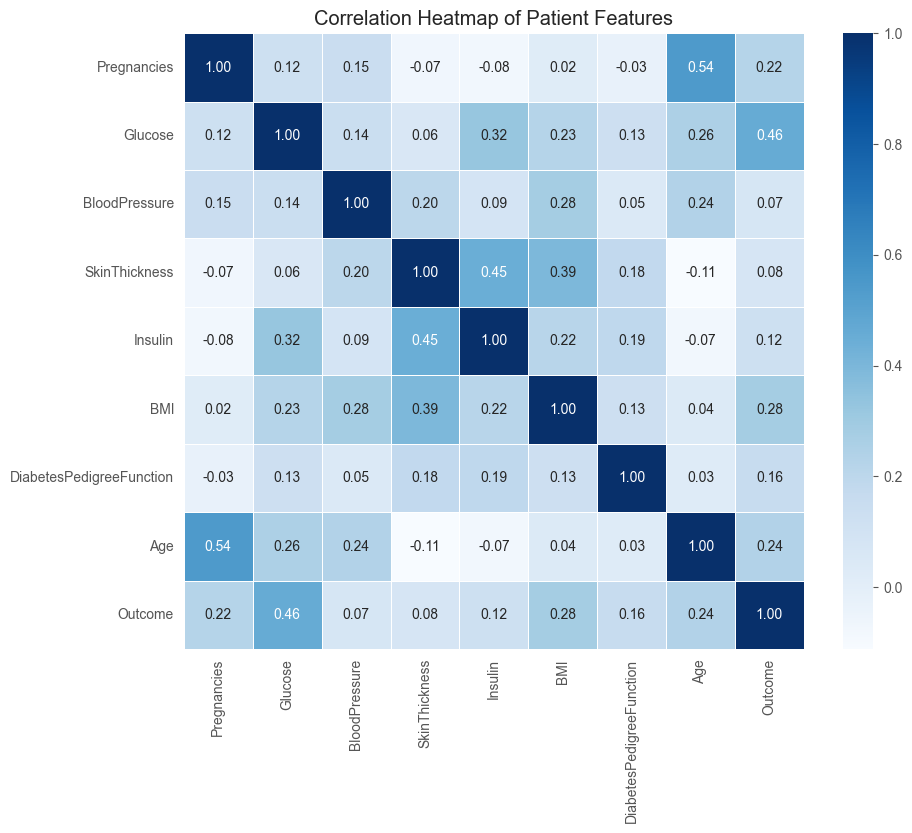

In [58]:
# Plot 2: Correlation Heatmap
print("\n--- Plotting Correlation Matrix ---")
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Patient Features')
plt.show()


--- Plotting Outliers using Boxplots ---


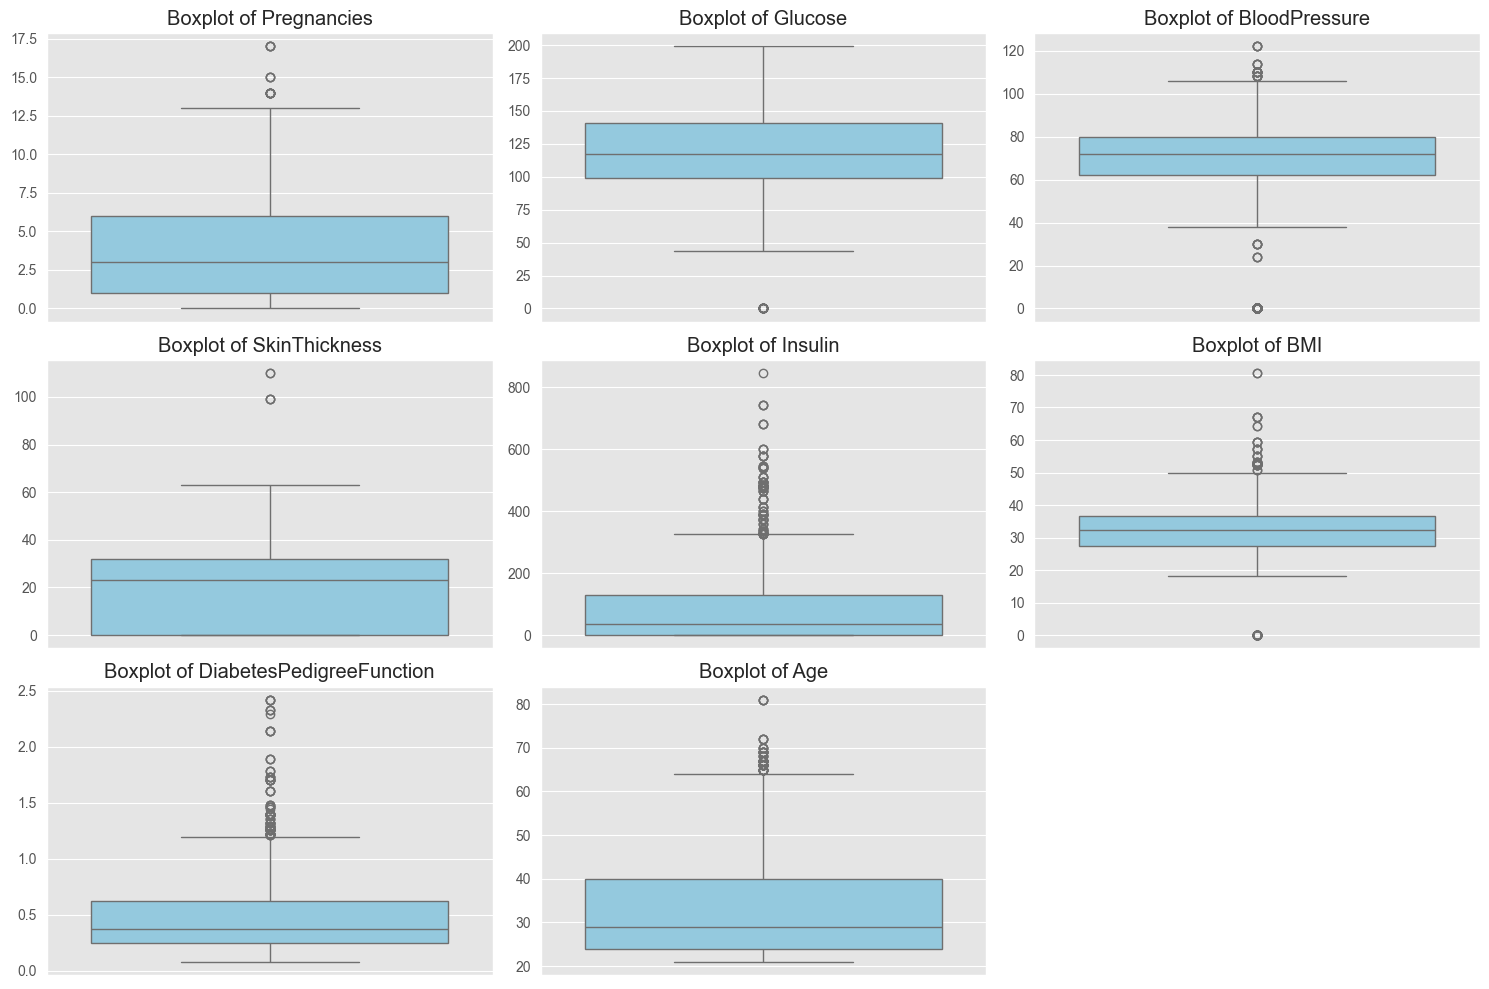

In [59]:
# ==========================================
# 3. Visualizing Outliers (Boxplots)
# ==========================================
print("\n--- Plotting Outliers using Boxplots ---")
# We will create a boxplot for each feature to see the outliers (the dots outside the whiskers)

plt.figure(figsize=(15, 10))
for i, col in enumerate(df.columns[:-1], 1): # Exclude the 'Outcome' column
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [60]:
# ==========================================
# 3. Data Preprocessing
# ==========================================
print("\n--- Preprocessing Data ---")
# Separate features (X) and target (y)
# We convert them to numpy arrays (.values) for our custom Random Forest
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values
df.isnull().sum()


--- Preprocessing Data ---


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [61]:
# ==========================================
# Outlier Treatment using IQR (Capping)
# ==========================================
print("--- Treating Outliers using Capping (IQR Method) ---")

# We will apply this to columns that usually have high outliers
features_with_outliers = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for col in features_with_outliers:
    # 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # 2. Calculate IQR (Interquartile Range)
    IQR = Q3 - Q1

    # 3. Define the lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # 4. Cap the outliers (Replace values outside the bounds with the bounds themselves)
    # np.where(condition, value_if_true, value_if_false)
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])

print("\n--- Outliers Successfully Capped! ---")

# If you run the describe() or boxplot code after this, you will see the max values are now completely normal!
print("\n--- Statistical Summary AFTER Outlier Treatment ---")
display(df.describe())

--- Treating Outliers using Capping (IQR Method) ---

--- Outliers Successfully Capped! ---

--- Statistical Summary AFTER Outlier Treatment ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000
mean,3.734465,121.336705,70.690751,20.782153,74.895954,32.228527,0.459436,33.037572,0.343931
std,3.296121,31.272866,14.095514,15.870178,94.198562,7.118825,0.284419,11.494410,0.475104
min,0.000000,36.000000,35.000000,0.000000,0.000000,13.312500,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.244000,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,37.000000,32.200000,0.375000,29.000000,0.000000
75%,6.000000,141.000000,80.000000,32.000000,130.000000,36.625000,0.624000,40.000000,1.000000
max,13.500000,199.000000,107.000000,80.000000,325.000000,50.612500,1.194000,64.000000,1.000000



--- Plotting Outliers using Boxplots ---


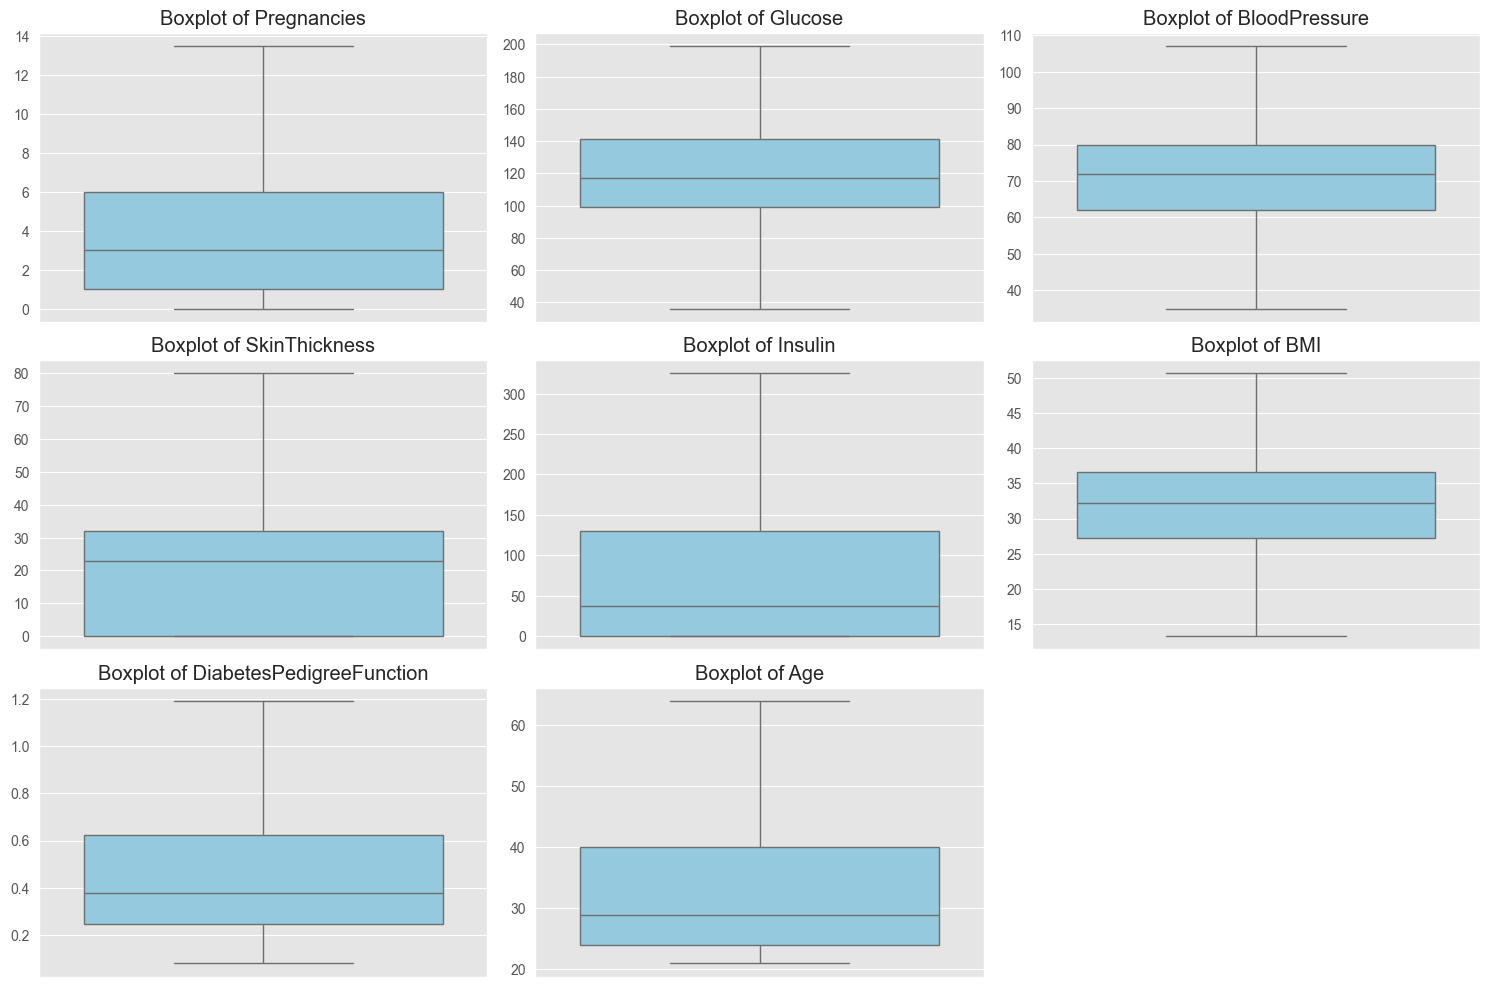

In [62]:
# ==========================================
# 3. Visualizing Outliers (Boxplots)
# ==========================================
print("\n--- Plotting Outliers using Boxplots ---")
# We will create a boxplot for each feature to see the outliers (the dots outside the whiskers)

plt.figure(figsize=(15, 10))
for i, col in enumerate(df.columns[:-1], 1): # Exclude the 'Outcome' column
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [63]:
# Split the data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Training set: 2214 samples
Testing set: 554 samples


In [64]:
# ==========================================
# 4. Custom Random Forest Implementation
# ==========================================
class CustomRandomForest:
    def __init__(self, n_trees=100, max_depth=15):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        for _ in range(self.n_trees):
            # 1. Bootstrap sampling (random sampling with replacement)
            X_sample, y_sample = self._bootstrap_data(X, y)

            # 2. Initialize Decision Tree
            # max_features="sqrt" ensures each tree looks at a random subset of features
            tree = DecisionTreeClassifier(max_depth=self.max_depth, max_features="sqrt")

            # 3. Train the tree
            tree.fit(X_sample, y_sample)

            # 4. Add to forest
            self.trees.append(tree)

    def _bootstrap_data(self, X, y):
        n_samples = X.shape[0]
        indices = np.random.choice(n_samples, n_samples, replace=True)
        return X[indices], y[indices]

    def predict(self, X):
        # Collect predictions from all trees in the forest
        tree_predictions = np.array([tree.predict(X) for tree in self.trees])

        # Swap axes so each row is a sample and columns are tree votes
        tree_predictions = np.swapaxes(tree_predictions, 0, 1)

        # Apply majority voting
        final_predictions = np.array([self._majority_vote(votes) for votes in tree_predictions])
        return final_predictions

    def _majority_vote(self, votes):
        counter = Counter(votes)
        most_common = counter.most_common(1)[0][0]
        return most_common

In [65]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ==========================================
# 5. Training and Evaluation
# ==========================================
print("\n--- Training Custom Random Forest ---")

# Initialize and train the model with 100 trees
rf_model = CustomRandomForest(n_trees=100, max_depth=15)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)
print("\n--- Training Custom Random Forest Finished ---")


--- Training Custom Random Forest ---

--- Training Custom Random Forest Finished ---



>>> Custom Random Forest Accuracy: 99.64% <<<

--- Classification Report ---
              precision    recall  f1-score   support

 Healthy (0)       1.00      1.00      1.00       364
Diabetic (1)       0.99      0.99      0.99       190

    accuracy                           1.00       554
   macro avg       1.00      1.00      1.00       554
weighted avg       1.00      1.00      1.00       554


--- Plotting Confusion Matrix ---


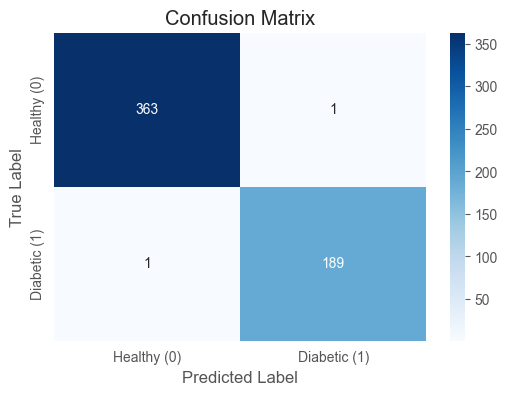

In [66]:
# ------------------------------------------
# A. Accuracy
# ------------------------------------------
acc = accuracy_score(y_test, y_pred)
print(f"\n>>> Custom Random Forest Accuracy: {acc * 100:.2f}% <<<\n")

# ------------------------------------------
# B. Classification Report
# ------------------------------------------
print("--- Classification Report ---")
# target_names makes the output easier to read
print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'Diabetic (1)']))

# ------------------------------------------
# C. Confusion Matrix Visualization
# ------------------------------------------
print("\n--- Plotting Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy (0)', 'Diabetic (1)'],
            yticklabels=['Healthy (0)', 'Diabetic (1)'])

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()